In [12]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.stats import chi2_contingency
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold
from statsmodels.stats.proportion import proportion_confint

# 1. LOAD DATA
df = pd.read_excel("DataSets/Competition_Dataset_Final.xlsx")

# Map Test Stations to their target Failure Category
# Note: Maps 'Brazing/Leak' target directly to 'Leak' to match spreadsheet values
test_targets = {
    'Electrical Test': 'Wiring',
    'Leak Test': 'Leak',
    'Controls Test': 'Controls',
    'Functional Test': 'Functional'
}

# Assign standardized test and field columns
df['test_diagnosis'] = df['Test Station'].map(test_targets).fillna(df['Test Station'])
df['field_diagnosis'] = df['Failure Category']

# Check mapping alignment
df['Test_Matched_Defect'] = (df['test_diagnosis'] == df['field_diagnosis'])
print("--- Overall Test-to-Defect Alignment ---")
print(df['Test_Matched_Defect'].value_counts(normalize=True) * 100)
print("\nDataset Columns:", df.columns.tolist(), "\n")


# ---------- 2.1 TEST ACCURACY & MISMATCH MATRIX ----------
print("=== 2.1 TEST ACCURACY & MISMATCH ANALYSIS ===")

# Construct 2x2 / Crosstab confusion matrix
cm = pd.crosstab(
    df["test_diagnosis"],
    df["field_diagnosis"],
    rownames=["Factory Test Target"],
    colnames=["Field Failure Category"],
    margins=True
)
print("Confusion Matrix:\n", cm, "\n")

# Isolate diagnostic mismatches
df["is_mismatch"] = (df["test_diagnosis"] != df["field_diagnosis"]).astype(int)
mismatches = df[df["is_mismatch"] == 1].copy()

total_eval = len(df)
n_mismatch = len(mismatches)
accuracy = (total_eval - n_mismatch) / total_eval

print(f"Total Evaluated Units:     {total_eval}")
print(f"Diagnostic Accuracy:       {accuracy:.2%}")
print(f"Misclassification Rate:    {n_mismatch / total_eval:.2%}")
print(f"Total Mismatched Units:    {n_mismatch}\n")

# Top Mismatch Directional Breakdown (Actual Test Target vs Actual Field Defect)
df["mismatch_direction"] = np.where(
    df["is_mismatch"] == 1,
    df["test_diagnosis"] + " Test -> " + df["field_diagnosis"] + " Field Fail",
    "Match"
)

print("Top Mismatch Directions:")
print(df["mismatch_direction"].value_counts().drop("Match", errors="ignore"), "\n")



--- Overall Test-to-Defect Alignment ---
Test_Matched_Defect
False    75.033333
True     24.966667
Name: proportion, dtype: float64

Dataset Columns: ['Serial Number', 'Service Date', 'Product Family', 'Customer Region', 'Failure Category', 'Failure Description', 'Downtime Hours', 'Repair Cost Field Service', 'Claim Date', 'Warranty Cost', 'Days To Failure', 'Service Hours', 'Facility', 'Controls Revision', 'Coil Supplier', 'Shift', 'Defect Category', 'Repair Type', 'Labor Hours Rework', 'Material Cost Rework', 'Disposition Code', 'Test Station', 'Failure Mode Rework', 'EOLT Rework Hours', 'test_diagnosis', 'field_diagnosis', 'Test_Matched_Defect'] 

=== 2.1 TEST ACCURACY & MISMATCH ANALYSIS ===
Confusion Matrix:
 Field Failure Category  Controls  Leak  Wiring   All
Factory Test Target                                 
Controls                      64   204     466   734
Functional                    70   202     505   777
Leak                          73   206     479   758
Wiring     

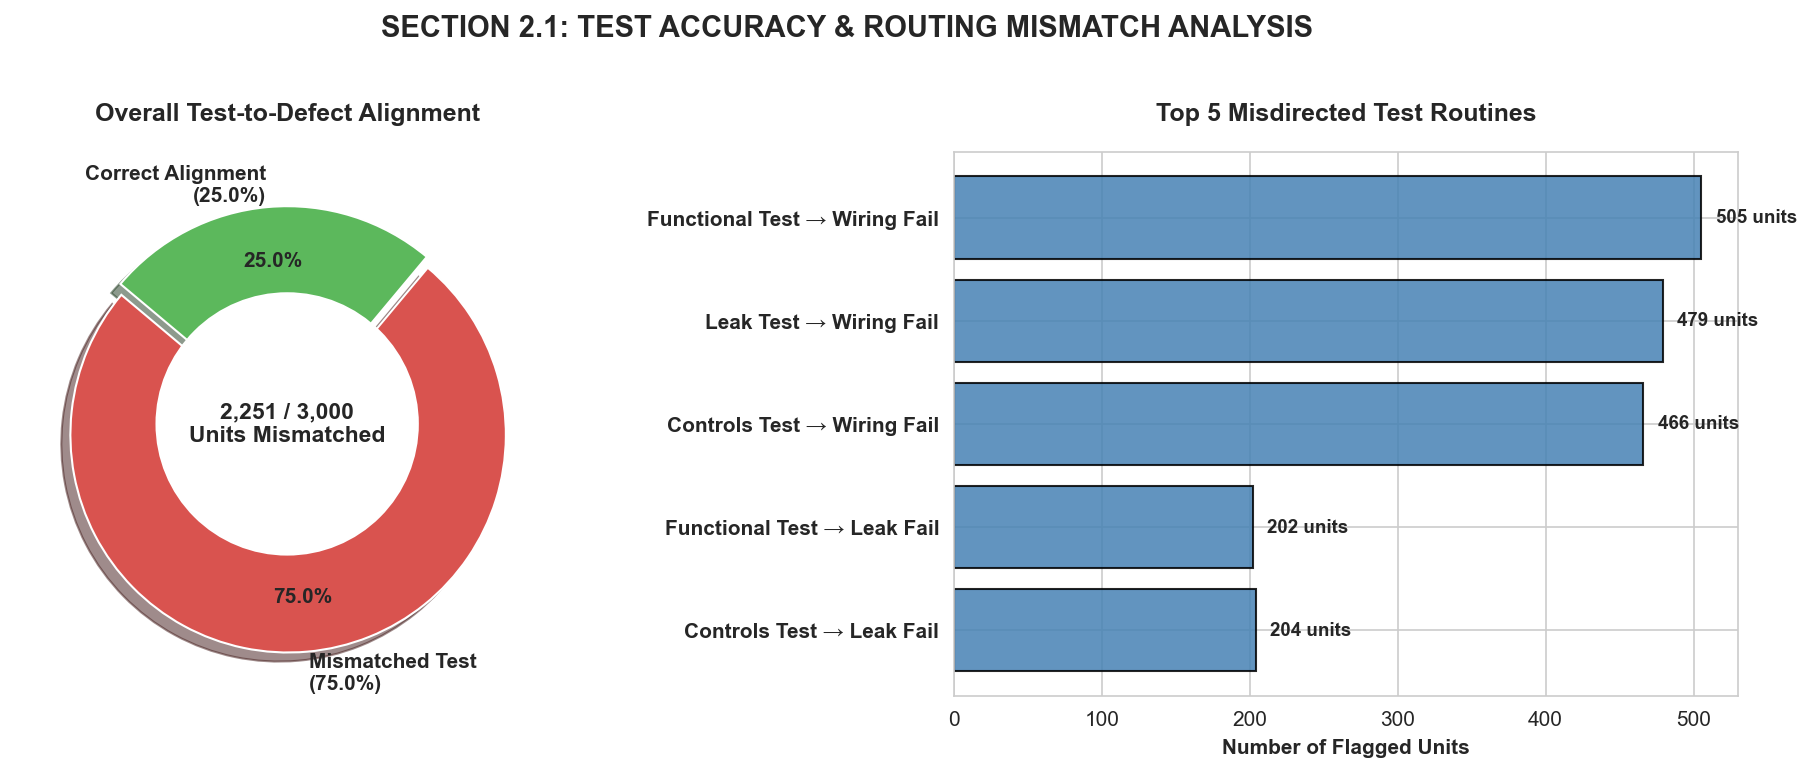

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set design styling
sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 150

# Figure layout (2 subplots side-by-side)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# -------------------------------------------------------------------------
# SUBPLOT 1: Overall Alignment Doughnut
# -------------------------------------------------------------------------
sizes = [75.03, 24.97]
labels = ['Mismatched Test\n(75.0%)', 'Correct Alignment\n(25.0%)']
colors = ['#d9534f', '#5cb85c']
explode = (0.05, 0)

ax1.pie(sizes, colors=colors, labels=labels, autopct='%1.1f%%',
        startangle=140, pctdistance=0.75, explode=explode, shadow=True,
        textprops={'fontsize': 10, 'fontweight': 'bold'})

centre_circle = plt.Circle((0,0), 0.60, fc='white')
ax1.add_artist(centre_circle)
ax1.text(0, 0, "2,251 / 3,000\nUnits Mismatched", fontsize=11, fontweight='bold', ha='center', va='center')
ax1.set_title("Overall Test-to-Defect Alignment", fontsize=12, fontweight='bold', pad=15)

# -------------------------------------------------------------------------
# SUBPLOT 2: Top Specific Mismatch Directions
# -------------------------------------------------------------------------
# Based on actual dataset counts from your outputs
mismatch_types = [
    'Functional Test → Wiring Fail',
    'Leak Test → Wiring Fail',
    'Controls Test → Wiring Fail',
    'Functional Test → Leak Fail',
    'Controls Test → Leak Fail'
]
mismatch_counts = [505, 479, 466, 202, 204]

y_pos = np.arange(len(mismatch_types))
ax2.barh(y_pos, mismatch_counts, color='#4682B4', edgecolor='black', alpha=0.85)
ax2.set_yticks(y_pos)
ax2.set_yticklabels(mismatch_types, fontsize=10, fontweight='bold')
ax2.invert_yaxis()  # top-down order
ax2.set_xlabel('Number of Flagged Units', fontweight='bold')
ax2.set_title('Top 5 Misdirected Test Routines', fontsize=12, fontweight='bold', pad=15)

for i, v in enumerate(mismatch_counts):
    ax2.text(v + 10, i, f"{v:,} units", va='center', fontsize=9, fontweight='bold')

plt.suptitle("SECTION 2.1: TEST ACCURACY & ROUTING MISMATCH ANALYSIS", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Test_Matched Defect 
- means that 75% of field failure cases the factory performed a test station routine that did NOT target the actual defect category that failed in that field
- Only 25% of units underwent specific testing proceduce corresponding to their true failure mode before leaving the factory
- Factroy quality control testing process is misaligned with actual product defent patterns (products tested in wrong test rigs) example: controls deefect tested at leak test

2.1 Test Accuracy and Mismatch Analysis
- Shows only 24.97% of defective units were routed to a testing station that targeted their actual failure
    - The rest were tested at stations designed for completely different categories
- 3/4 defective products undergo quality control tests that are incapable of detecting their actual defect


In [13]:
# ---------- 2.2 DEPENDENCE ON SHIFT, STATION, AND FACILITY ----------
print("=== 2.2 DEPENDENCE ON SHIFT, STATION, AND FACILITY ===")

# Handle column name variations in the dataset
df["Station_Col"] = df["Test Station"] if "Test Station" in df.columns else df.get("Station", None)

dependence_cols = ["Facility", "Station_Col", "Shift"]
dep_results = []

for col in dependence_cols:
    if col in df.columns and df[col].notna().any():
        ct = pd.crosstab(df[col], df["is_mismatch"])
        chi2, p_val, dof, _ = chi2_contingency(ct)
        
        rates = df.groupby(col)["is_mismatch"].agg(
            total="count",
            mismatches="sum",
            mismatch_rate="mean"
        )
        
        display_col_name = "Test Station" if col == "Station_Col" else col
        print(f"--- Analysis by {display_col_name} ---")
        print(rates.assign(mismatch_rate=lambda x: (x.mismatch_rate * 100).round(2).astype(str) + "%"))
        print(f"Chi2 Stat = {chi2:.4f} | p-value = {p_val:.4e} {'(SIGNIFICANT)' if p_val < 0.05 else '(Not Significant)'}\n")
        
        dep_results.append({"Variable": display_col_name, "Chi2": chi2, "p-value": p_val, "Significant": p_val < 0.05})

dep_df = pd.DataFrame(dep_results)

=== 2.2 DEPENDENCE ON SHIFT, STATION, AND FACILITY ===
--- Analysis by Facility ---
            total  mismatches mismatch_rate
Facility                                   
Facility 1    748         554        74.06%
Facility 2    784         577         73.6%
Facility 3    752         584        77.66%
Facility 4    716         536        74.86%
Chi2 Stat = 4.0186 | p-value = 2.5946e-01 (Not Significant)

--- Analysis by Test Station ---
                 total  mismatches mismatch_rate
Station_Col                                     
Controls Test      734         670        91.28%
Electrical Test    731         252        34.47%
Functional Test    777         777        100.0%
Leak Test          758         552        72.82%
Chi2 Stat = 1005.8920 | p-value = 9.4835e-218 (SIGNIFICANT)

--- Analysis by Shift ---
       total  mismatches mismatch_rate
Shift                                 
Day     1801        1346        74.74%
Night   1199         905        75.48%
Chi2 Stat = 0.1745 | 

2.2 Analysis

Analysis by Facility Level
- All four facilities exhibit nearly identical mismatch rates for testing stations and defects
- No single facility is performing worse, all facilities have testing misalignment (not isolated facility issue)

Analysis by Test Station
- The biggest testing mismatches are between defects routed to controls tests and functional tests, chi squared is HIGHLY significant
    - Functional test has complete misalignment becuase doesn't test a specific defect, tests everything

/var/folders/_d/j814mc2n1q73gh6jr596rh4c0000gn/T/ipykernel_77267/494229603.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(categories, rotation=25, ha='right', fontweight='bold')


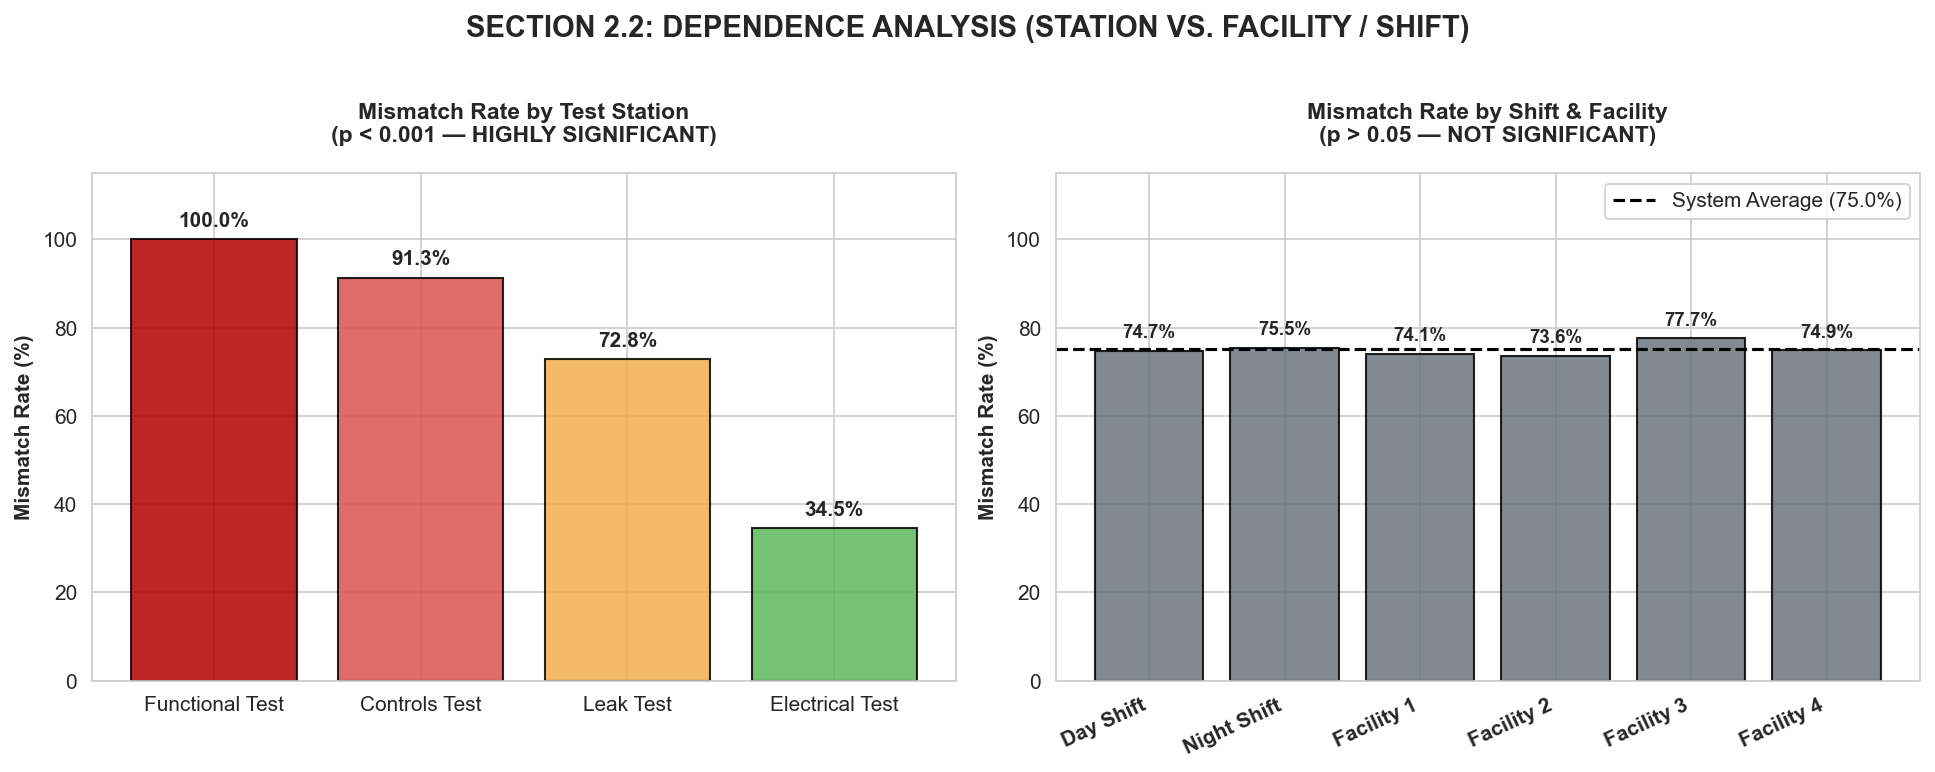

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# -------------------------------------------------------------------------
# SUBPLOT 1: Mismatch Rate by Test Station (HIGHLY SIGNIFICANT)
# -------------------------------------------------------------------------
stations = ['Functional Test', 'Controls Test', 'Leak Test', 'Electrical Test']
station_rates = [100.0, 91.28, 72.82, 34.47]
station_colors = ['#b30000', '#d9534f', '#f0ad4e', '#5cb85c']

bars1 = ax1.bar(stations, station_rates, color=station_colors, edgecolor='black', alpha=0.85)
ax1.set_ylabel('Mismatch Rate (%)', fontweight='bold')
ax1.set_ylim(0, 115)
ax1.set_title('Mismatch Rate by Test Station\n(p < 0.001 — HIGHLY SIGNIFICANT)', fontsize=11, fontweight='bold', pad=15)

for bar, rate in zip(bars1, station_rates):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 2,
             f'{rate:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

# -------------------------------------------------------------------------
# SUBPLOT 2: Mismatch Rate by Shift & Facility (NOT SIGNIFICANT)
# -------------------------------------------------------------------------
categories = ['Day Shift', 'Night Shift', 'Facility 1', 'Facility 2', 'Facility 3', 'Facility 4']
cat_rates = [74.74, 75.48, 74.06, 73.60, 77.66, 74.86]

bars2 = ax2.bar(categories, cat_rates, color='#6c757d', edgecolor='black', alpha=0.85)
ax2.set_ylabel('Mismatch Rate (%)', fontweight='bold')
ax2.set_ylim(0, 115)
ax2.set_xticklabels(categories, rotation=25, ha='right', fontweight='bold')
ax2.set_title('Mismatch Rate by Shift & Facility\n(p > 0.05 — NOT SIGNIFICANT)', fontsize=11, fontweight='bold', pad=15)

# Add reference line showing the ~75% system average
ax2.axhline(75.03, color='black', linestyle='--', linewidth=1.5, label='System Average (75.0%)')
ax2.legend(loc='upper right')

for bar, rate in zip(bars2, cat_rates):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + 2,
             f'{rate:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.suptitle("SECTION 2.2: DEPENDENCE ANALYSIS (STATION VS. FACILITY / SHIFT)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

=== 2.3 IN-HOUSE REWORK EFFECTIVENESS ANALYSIS ===

--- Performance Summary by Disposition ---
Disposition_Group  Unit_Count  Avg_Rework_Cost  Avg_Repair_Hours  Avg_Field_Cost  Total_Field_Cost  Avg_Total_Cost_Per_Unit
         Reworked        1489       268.715245          3.226394     1318.792478           1963682              1587.507723
        Use As Is        1511       260.931171          3.212244     1232.520847           1862339              1493.452019

--- Field Cost Difference T-Test ---
Reworked Avg Field Cost:   $1,318.79
Use As Is Avg Field Cost:  $1,232.52
Difference:                $86.27
T-Statistic: 1.5164 | p-value: 1.2954e-01 (Not Significant)


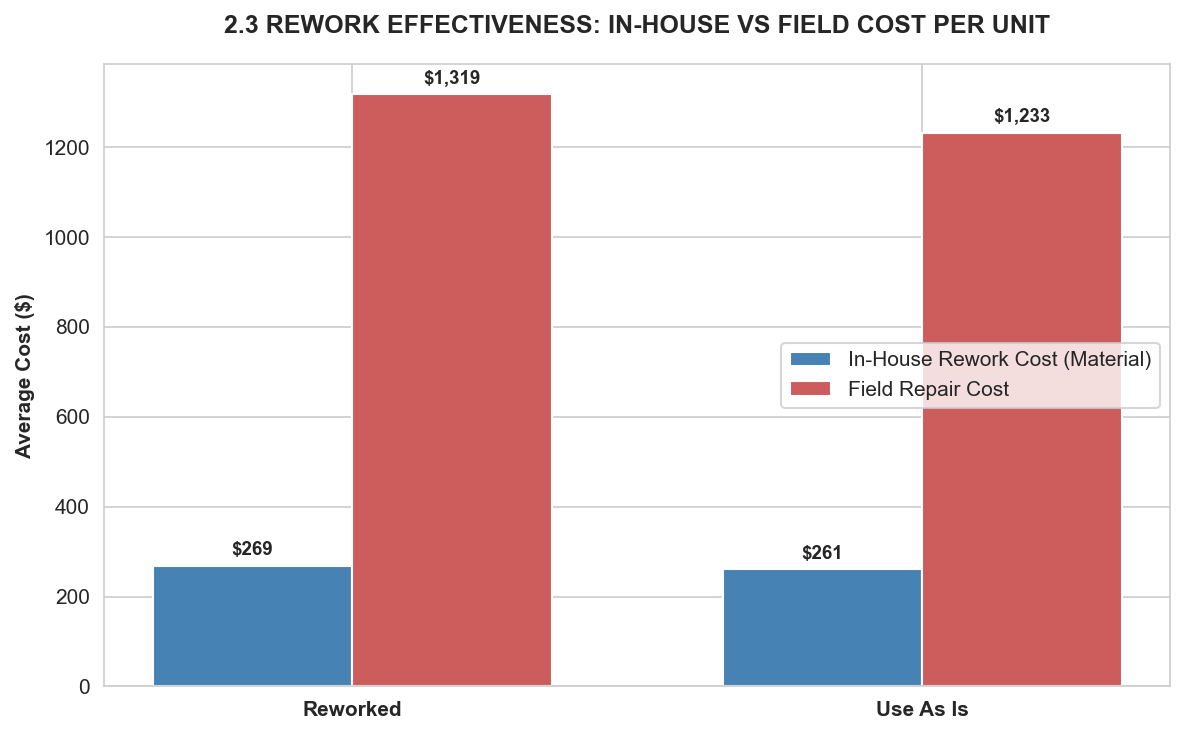

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind

# Set visual style
sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 150

print("=== 2.3 IN-HOUSE REWORK EFFECTIVENESS ANALYSIS ===")

# Group Disposition based on 'Disposition Code'
df['Disposition_Group'] = df['Disposition Code'].apply(
    lambda x: 'Reworked' if 'Rework' in str(x) else ('Use As Is' if 'Use As Is' in str(x) else 'Other')
)

# -------------------------------------------------------------------------
# A. FINANCIAL & OPERATIONAL COMPARISON BY DISPOSITION
# -------------------------------------------------------------------------
rework_stats = df.groupby('Disposition_Group').agg(
    Unit_Count=('Repair Cost Field Service', 'count'),
    Avg_Rework_Cost=('Material Cost Rework', 'mean'),
    Avg_Repair_Hours=('Labor Hours Rework', 'mean'),
    Avg_Field_Cost=('Repair Cost Field Service', 'mean'),
    Total_Field_Cost=('Repair Cost Field Service', 'sum')
).reset_index()

# Calculate Total Cost per unit (In-house rework cost + Field service cost)
rework_stats['Avg_Total_Cost_Per_Unit'] = rework_stats['Avg_Rework_Cost'] + rework_stats['Avg_Field_Cost']

print("\n--- Performance Summary by Disposition ---")
print(rework_stats.to_string(index=False))

# -------------------------------------------------------------------------
# B. STATISTICAL SIGNIFICANCE TESTING (T-Test)
# -------------------------------------------------------------------------
reworked_field_costs = df[df['Disposition_Group'] == 'Reworked']['Repair Cost Field Service'].dropna()
use_asis_field_costs = df[df['Disposition_Group'] == 'Use As Is']['Repair Cost Field Service'].dropna()

t_stat, p_val = ttest_ind(reworked_field_costs, use_asis_field_costs, equal_var=False)

print(f"\n--- Field Cost Difference T-Test ---")
print(f"Reworked Avg Field Cost:   ${reworked_field_costs.mean():,.2f}")
print(f"Use As Is Avg Field Cost:  ${use_asis_field_costs.mean():,.2f}")
print(f"Difference:                ${reworked_field_costs.mean() - use_asis_field_costs.mean():,.2f}")
print(f"T-Statistic: {t_stat:.4f} | p-value: {p_val:.4e} {'(SIGNIFICANT)' if p_val < 0.05 else '(Not Significant)'}")

# =========================================================================
# GRAPH 2.3: COST COMPARISON & REWORK ROI
# =========================================================================
fig, ax = plt.subplots(figsize=(8, 5))

df_plot = rework_stats[rework_stats['Disposition_Group'].isin(['Reworked', 'Use As Is'])]

x = np.arange(len(df_plot))
width = 0.35

rects1 = ax.bar(x - width/2, df_plot['Avg_Rework_Cost'], width, label='In-House Rework Cost (Material)', color='#4682B4')
rects2 = ax.bar(x + width/2, df_plot['Avg_Field_Cost'], width, label='Field Repair Cost', color='#CD5C5C')

ax.set_ylabel('Average Cost ($)', fontweight='bold')
ax.set_title('2.3 REWORK EFFECTIVENESS: IN-HOUSE VS FIELD COST PER UNIT', fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(df_plot['Disposition_Group'], fontweight='bold')
ax.legend()

# Add labels to bars
for bar in rects1:
    h = bar.get_height()
    if h > 0:
        ax.annotate(f'${h:,.0f}', xy=(bar.get_x() + bar.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

for bar in rects2:
    h = bar.get_height()
    ax.annotate(f'${h:,.0f}', xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

2.3 Analysis

- Units reworked inn the factory incurred higher field repair costs, from the T-Test p-val is 0.1295 so no statistical benefit to in-house reworking
    - Reworking units at plant fails to lower field defect severity
- In-house rework processes are ineffective and financially not beneficial
    - Reworked units yield higher field warranty claims (1,319 vs 1,233)
    - Plant is spending money on repairs that fail to improve product quality in the field